# Hands-on 2 — Build, Serialize & Navigate an RDF Graph
_SAP Knowledge Graphs & Ontologies — Foundation | Hands-on 2_

## Run this notebook
This notebook runs in **Databricks, Jupyter, or any Python 3 environment** — the first cell `%pip install`s everything it needs. Run the cells top to bottom.

## Business scenario
We model the **metadata** of an SAP-style procurement OData service: which service exists, the entity set it exposes, the entity type behind it, that type's properties, and the navigation to related items. This is **context about what the API exposes and how it connects** — not the purchase-order records themselves, which live in the LoB system and are fetched via a tool call. Along the way we build the ideas you use on every real graph:

1. An **RDFS class & property hierarchy** (`EntitySet ⊑ DataExposure`) with **domain/range**.
2. **Typed and multilingual literals** — EDM type strings, max-length integers, language-tagged labels.
3. `.add()` vs `.set()`, and **merging** two graphs into one.
4. **Navigation helpers** — walk the graph by subject/predicate/object.
5. Serialize to **Turtle** and **visualize** with `networkx`.

In [1]:
%pip install rdflib networkx matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 12.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 17.6 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 16.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 17.3 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]

[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
# On Databricks, you may need to restart Python so the installs take effect:
# dbutils.library.restartPython()

### Step 1 — Namespaces and an empty graph

In [2]:
from rdflib import Graph, Namespace, Literal, RDF, RDFS, URIRef
from rdflib.namespace import XSD

# Canonical metadata vocabulary + base IRIs.
ODATA = Namespace('http://example.org/odata#')
BASE = 'http://data.example.org'
g = Graph()
g.bind('odata', ODATA)
print('Empty graph created:', len(g), 'triples')

Empty graph created: 0 triples


### Step 2 — Declare an RDFS class & property hierarchy
An `EntitySet` is a kind of `DataExposure` (a general concept for anything a service exposes). We also declare the core metadata classes — `Service`, `EntityType`, `Property`, `Navigation` — and give each property a **domain** (the class of its subject) and **range** (the class of its object). Domain/range document intent and let a reasoner infer types.

In [3]:
# Classes
g.add((ODATA.DataExposure, RDF.type, RDFS.Class))
g.add((ODATA.EntitySet, RDF.type, RDFS.Class))
g.add((ODATA.EntitySet, RDFS.subClassOf, ODATA.DataExposure))
g.add((ODATA.Service, RDF.type, RDFS.Class))
g.add((ODATA.EntityType, RDF.type, RDFS.Class))
g.add((ODATA.Property, RDF.type, RDFS.Class))
g.add((ODATA.Navigation, RDF.type, RDFS.Class))

# Properties with domain and range
g.add((ODATA.entityType, RDFS.domain, ODATA.EntitySet))
g.add((ODATA.entityType, RDFS.range, ODATA.EntityType))
g.add((ODATA.property, RDFS.domain, ODATA.EntityType))
g.add((ODATA.property, RDFS.range, ODATA.Property))
g.add((ODATA.navigateTo, RDFS.domain, ODATA.Navigation))
g.add((ODATA.navigateTo, RDFS.range, ODATA.EntityType))

print(len(g), 'schema triples')

13 schema triples


### Step 3 — Add typed and multilingual literals
Metadata is more than links. Literals carry **typed values** (a `maxLength` integer, an EDM type string, a version) and **language tags** (a label in English and German). Note how `Literal(..., datatype=...)` and `Literal(..., lang=...)` attach that metadata. We populate the canonical `API_PURCHASEORDER_2` service: its `PurchaseOrder` entity set, the entity type behind it, a key property, and the navigation to items.

In [4]:
svc  = URIRef(f'{BASE}/Service/API_PURCHASEORDER_2')
eset = URIRef(f'{BASE}/Service/API_PURCHASEORDER_2/EntitySet/PURCHASEORDER')
etyp = URIRef(f'{BASE}/Service/API_PURCHASEORDER_2/EntityType/PURCHASEORDER_TYPE')
prop = URIRef(f'{BASE}/Service/API_PURCHASEORDER_2/EntityType/PURCHASEORDER_TYPE/Property/PurchaseOrder')
nav  = URIRef(f'{BASE}/Service/API_PURCHASEORDER_2/EntityType/PURCHASEORDER_TYPE/Navigation/_PurchaseOrderItem')
itemtyp = URIRef(f'{BASE}/Service/API_PURCHASEORDER_2/EntityType/PURCHASEORDERITEM_TYPE')

# Service with a bilingual label
g.add((svc, RDF.type, ODATA.Service))
g.add((svc, ODATA.name, Literal('API_PURCHASEORDER_2')))
g.add((svc, RDFS.label, Literal('Purchase Order API', lang='en')))
g.add((svc, RDFS.label, Literal('Bestellungs-API', lang='de')))

# EntitySet backed by an EntityType
g.add((eset, RDF.type, ODATA.EntitySet))
g.add((eset, RDFS.label, Literal('PurchaseOrder entity set', lang='en')))
g.add((eset, ODATA.entityType, etyp))

# EntityType owns a property and a navigation
g.add((etyp, RDF.type, ODATA.EntityType))
g.add((etyp, RDFS.label, Literal('PurchaseOrder entity type', lang='en')))
g.add((etyp, ODATA.property, prop))

# Property with typed literals (EDM type + max length + key flag)
g.add((prop, RDF.type, ODATA.Property))
g.add((prop, ODATA.name, Literal('PurchaseOrder')))
g.add((prop, ODATA.type, Literal('Edm.String')))
g.add((prop, ODATA.maxLength, Literal('10', datatype=XSD.integer)))
g.add((prop, ODATA.odataKey, Literal(True)))

# Navigation edge to the item entity type
g.add((nav, RDF.type, ODATA.Navigation))
g.add((nav, ODATA.navigateFrom, etyp))
g.add((nav, ODATA.navigateTo, itemtyp))
g.add((nav, ODATA.multiplicity, Literal('*')))

print(f'Graph now has {len(g)} triples')

Graph now has 32 triples


### Step 4 — `.add()` vs `.set()`
`g.add()` **appends** a triple — add two `maxLength` values and both are kept, which is usually wrong for a single-valued fact (a property has one max length). `g.set()` **replaces** any existing value for that (subject, predicate). Watch the count.

In [5]:
# Mistakenly append a second max length with add() -> now there are TWO values
g.add((prop, ODATA.maxLength, Literal('40', datatype=XSD.integer)))
lengths = list(g.objects(prop, ODATA.maxLength))
print('After add(), maxLength values:', [str(t) for t in lengths])

# set() collapses it back to a single authoritative value
g.set((prop, ODATA.maxLength, Literal('10', datatype=XSD.integer)))
lengths = list(g.objects(prop, ODATA.maxLength))
print('After set(), maxLength values:', [str(t) for t in lengths])

After add(), maxLength values: ['10', '40']
After set(), maxLength values: ['10']


### Step 5 — Merge two graphs
Real knowledge graphs are assembled from many sources. Here a second graph carries a metadata update from a later crawl of the service document — a version string and a description; merging (`g += delta`) unions the triples into one graph — the foundation of how independently-maintained domain graphs combine.

In [6]:
delta = Graph(); delta.bind('odata', ODATA)
delta.add((svc, ODATA.version, Literal('0002')))
delta.add((eset, ODATA.description, Literal('Purchase orders exposed by the procurement API', lang='en')))

before = len(g)
g += delta   # graph merge (set union of triples)
print(f'Merged {len(delta)} new triples: {before} -> {len(g)}')

Merged 2 new triples: 32 -> 34


### Step 6 — Navigate the graph
rdflib lets you walk triples by any position: `objects(s, p)`, `subjects(p, o)`, `predicate_objects(s)`. This is graph *navigation* — following relationships, the core move a knowledge graph enables.

In [7]:
print('All facts about the API_PURCHASEORDER_2 service:')
for p, o in g.predicate_objects(svc):
    print(f'  {str(p).split("/")[-1].split("#")[-1]:16} -> {o}')

print('\nWhich entity set is backed by the PurchaseOrder entity type?')
for s in g.subjects(ODATA.entityType, etyp):
    label = g.value(s, RDFS.label)  # value() returns one object (or None)
    print(' ', s.split('/')[-1], '/', label)

print('\nEnglish labels only:')
for s, o in g.subject_objects(RDFS.label):
    if getattr(o, 'language', None) == 'en':
        print(f'  {s.split("/")[-1]:22} = {o}')

All facts about the API_PURCHASEORDER_2 service:
  type             -> http://example.org/odata#Service
  name             -> API_PURCHASEORDER_2
  label            -> Purchase Order API
  label            -> Bestellungs-API
  version          -> 0002

Which entity set is backed by the PurchaseOrder entity type?
  PURCHASEORDER / PurchaseOrder entity set

English labels only:
  API_PURCHASEORDER_2    = Purchase Order API
  PURCHASEORDER          = PurchaseOrder entity set
  PURCHASEORDER_TYPE     = PurchaseOrder entity type


### Step 7 — Serialize to Turtle

In [8]:
print(g.serialize(format='turtle'))

@prefix odata: <http://example.org/odata#> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

odata:DataExposure a rdfs:Class .

odata:EntitySet a rdfs:Class ;
    rdfs:subClassOf odata:DataExposure .

odata:EntityType a rdfs:Class .

odata:Navigation a rdfs:Class .

odata:Property a rdfs:Class .

odata:Service a rdfs:Class .

<http://data.example.org/Service/API_PURCHASEORDER_2> a odata:Service ;
    rdfs:label "Bestellungs-API"@de,
        "Purchase Order API"@en ;
    odata:name "API_PURCHASEORDER_2" ;
    odata:version "0002" .

<http://data.example.org/Service/API_PURCHASEORDER_2/EntitySet/PURCHASEORDER> a odata:EntitySet ;
    rdfs:label "PurchaseOrder entity set"@en ;
    odata:description "Purchase orders exposed by the procurement API"@en ;
    odata:entityType <http://data.example.org/Service/API_PURCHASEORDER_2/EntityType/PURCHASEORDER_TYPE> .

<http://data.example.org/Service/API_PURCHASEORDER_2/EntityType/PURCHASEO

### Step 8 — Visualize with networkx
Convert the triples into a directed graph and draw it. We shorten IRIs to local names and skip literal-valued edges so the picture stays about the *entities and their links*.

Matplotlib is building the font cache; this may take a moment.
/var/folders/hb/9f88t7n14654_h2tgsf1y_hh0000gn/T/ipykernel_77744/2169118787.py:20: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


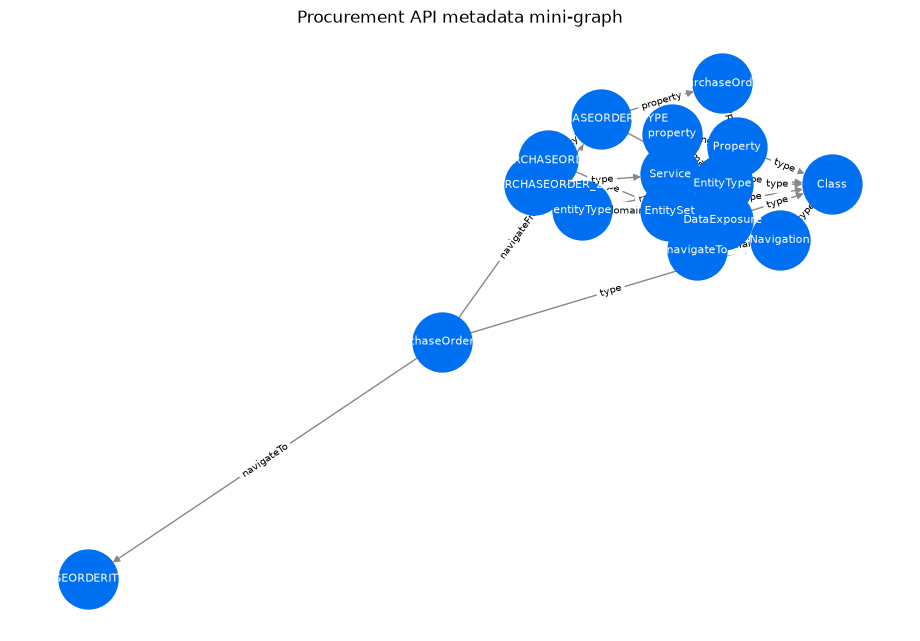

In [9]:
import networkx as nx
import matplotlib.pyplot as plt
from rdflib import Literal as RDFLiteral

def short(term):
    return str(term).rsplit('/', 1)[-1].rsplit('#', 1)[-1]

nxg = nx.DiGraph()
for s, p, o in g:
    if isinstance(o, RDFLiteral):
        continue  # keep the drawing to entity-to-entity relationships
    nxg.add_edge(short(s), short(o), label=short(p))

plt.figure(figsize=(9, 6))
pos = nx.spring_layout(nxg, seed=42)
nx.draw(nxg, pos, with_labels=True, node_color='#0070F2', node_size=1800,
        font_color='white', font_size=8, edge_color='#888')
nx.draw_networkx_edge_labels(nxg, pos, edge_labels=nx.get_edge_attributes(nxg, 'label'), font_size=7)
plt.title('Procurement API metadata mini-graph')
plt.tight_layout()
plt.show()

### 🧪 Try it — reshape the graph

Build intuition (not graded):

- Add a **new property** (or a second entity type) with `g.add(...)` triples of your own, then re-run the Step 6 navigation and Step 7 Turtle serialization — your metadata node should appear.
- Swap an `.add()` for a `.set()` on a single-valued property (like `odata:maxLength`) and watch the earlier value get replaced.

In [10]:
# 🧪 Your experiment. Example: list every subject that has an rdfs:label, with its label.
for s, label in g.subject_objects(RDFS.label):
    print(s.split('/')[-1], '->', label)

API_PURCHASEORDER_2 -> Purchase Order API
API_PURCHASEORDER_2 -> Bestellungs-API
PURCHASEORDER -> PurchaseOrder entity set
PURCHASEORDER_TYPE -> PurchaseOrder entity type


### 🔗 SAP bridge
This in-memory triple store stands in for a **W3C-standard RDF/SPARQL triple store** — the kind of engine a follow-up course covers. What it holds is **metadata/context**: which service exists, the entity set it exposes, the entity type behind it, that type's properties, and the navigation an agent traverses. The actual purchase-order records are *not* here — they live in the LoB system and are fetched via a tool call at run time. The `rdfs:subClassOf` link you added (`EntitySet` ⊑ `DataExposure`) is the seed of a **shared enterprise vocabulary**: define a class once, let each domain specialize. Domain/range, typed literals, and graph merge are exactly the mechanics SAP's teams use as they converge separate domain graphs toward one logical knowledge graph over time. Turtle is the vendor-neutral format those graphs use to interoperate.

## Recap
- You built a **typed RDF graph** of OData **metadata** with an RDFS class hierarchy and **domain/range** on properties.
- **Typed literals** (`xsd:integer` max length, EDM type strings) and **language-tagged** labels carry meaning beyond plain links.
- `.add()` appends; `.set()` replaces — use `set()` for single-valued facts like `odata:maxLength`.
- **Merging** graphs (`g += delta`) unions triples — how many sources become one graph.
- **Navigation** (`objects`/`subjects`/`predicate_objects`/`value`) walks relationships.
- You serialized to **Turtle** and **visualized** with `networkx`.
- The graph holds **what the API exposes and how it connects**; the purchase-order records themselves stay in the LoB system, reached via a tool call.